# Used Car Price Prediction

## Exploratory Data Analysis (EDA)

**Objective:** Predict used-car listing prices in US dollars using vehicle characteristics.

**Dataset:** 4,009 rows and 12 columns.  
**Problem type:** Supervised regression.  
**Target:** `price`.

### EDA Tasks
- Inspect sample rows and data types.
- Check missing values and duplicates.
- Explore numerical distributions and categorical counts.
- Examine extreme values and relationships with price.
- Study correlations and record findings.

**Note:** Detailed EDA uses training data. Missing-value filling, encoding and model training follow later.

Import libraries and load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

df = pd.read_csv("used_cars.csv")

df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


Dataset size, column types and sample rows

In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

display(df.sample(5, random_state=42))

Number of rows: 4009
Number of columns: 12

Column names:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
2580,Lexus,IS 300 Base,2018,"50,992 mi.",Gasoline,260.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,A/T,White,Gray,At least 1 accident or damage reported,Yes,"$28,000"
3660,Chevrolet,Impala Base,2004,"64,500 mi.",Gasoline,180.0HP 3.4L V6 Cylinder Engine Gasoline Fuel,A/T,Beige,Beige,None reported,Yes,"$5,900"
897,RAM,2500 SLT,2017,"86,000 mi.",Diesel,350.0HP 6.7L Straight 6 Cylinder Engine Diesel...,6-Speed A/T,Gray,Gray,At least 1 accident or damage reported,Yes,"$41,000"
2091,Mercedes-Benz,SL-Class SL 550,2013,"24,933 mi.",Gasoline,429.0HP 4.6L 8 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Silver,Red,At least 1 accident or damage reported,Yes,"$40,250"
1044,Ford,Shelby GT350R Base,2018,"18,500 mi.",Gasoline,526.0HP 5.2L 8 Cylinder Engine Gasoline Fuel,M/T,Blue,Black,At least 1 accident or damage reported,Yes,"$77,999"


missing values

In [3]:
missing_summary = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing percentage": (df.isna().mean() * 100).round(2)
})

display(missing_summary.sort_values("Missing count", ascending=False))

,Missing count,Missing percentage
clean_title,596,14.87
fuel_type,170,4.24
accident,113,2.82
brand,0,0.00
model,0,0.00
model_year,0,0.00
milage,0,0.00
engine,0,0.00
transmission,0,0.00
ext_col,0,0.00


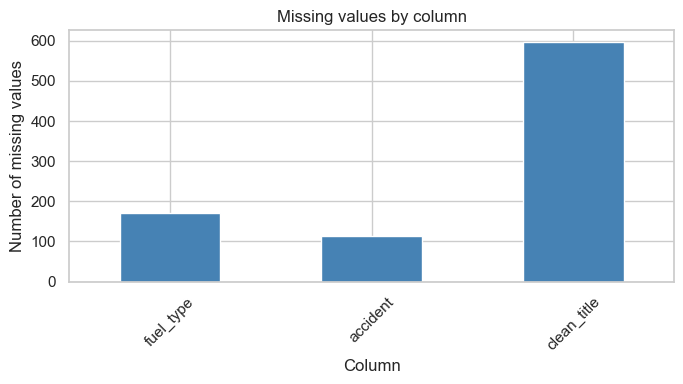

In [4]:
missing_columns = missing_summary[
    missing_summary["Missing count"] > 0
]

missing_columns["Missing count"].plot(
    kind="bar",
    figsize=(7, 4),
    color="steelblue"
)

plt.title("Missing values by column")
plt.xlabel("Column")
plt.ylabel("Number of missing values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Duplicates and unique values

In [5]:
print("Exact duplicate rows:", df.duplicated().sum())

unique_summary = pd.DataFrame({
    "Data type": df.dtypes.astype(str),
    "Unique non-missing values": df.nunique()
})

display(unique_summary)

Exact duplicate rows: 0


,Data type,Unique non-missing values
brand,object,57
model,object,1898
model_year,int64,34
milage,object,2818
fuel_type,object,7
engine,object,1146
transmission,object,62
ext_col,object,319
int_col,object,156
accident,object,2


Numerical values for exploration

In [6]:
from sklearn.model_selection import train_test_split

eda_data = df.copy()

eda_data["price"] = pd.to_numeric(
    eda_data["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

eda_data["milage"] = pd.to_numeric(
    eda_data["milage"]
    .str.replace("mi.", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

print("Missing numerical values after conversion:")
display(eda_data[["price", "milage"]].isna().sum())

# Reserve approximately 20% for final testing.
train_indices, test_indices = train_test_split(
    eda_data.index,
    test_size=0.20,
    random_state=42
)

eda = eda_data.loc[train_indices].copy()

print("Rows used for detailed EDA:", len(eda))
print("Rows reserved for final testing:", len(test_indices))

Missing numerical values after conversion:


price     0
milage    0
dtype: int64

Rows used for detailed EDA: 3207
Rows reserved for final testing: 802


Numerical summaries and suspicious values

In [7]:
numeric_columns = ["price", "milage", "model_year"]

display(
    eda[numeric_columns].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

print("Zero or negative prices:", (eda["price"] <= 0).sum())
print("Negative mileage:", (eda["milage"] < 0).sum())
print("Zero mileage:", (eda["milage"] == 0).sum())

print("\nModel-year range:")
print(eda["model_year"].min(), "to", eda["model_year"].max())

,price,milage,model_year
count,3207.00,3207.00,3207.00
mean,43125.76,64942.20,2015.56
std,51204.52,52433.52,6.03
min,2000.00,100.00,1974.00
25%,17050.00,23319.50,2012.00
50%,31300.00,53500.00,2017.00
75%,49999.00,93985.50,2020.00
90%,79993.20,137080.00,2022.00
95%,109970.00,165317.80,2023.00
99%,259470.00,224940.00,2023.00


Zero or negative prices: 0
Negative mileage: 0
Zero mileage: 0

Model-year range:
1974 to 2024


Price distribution

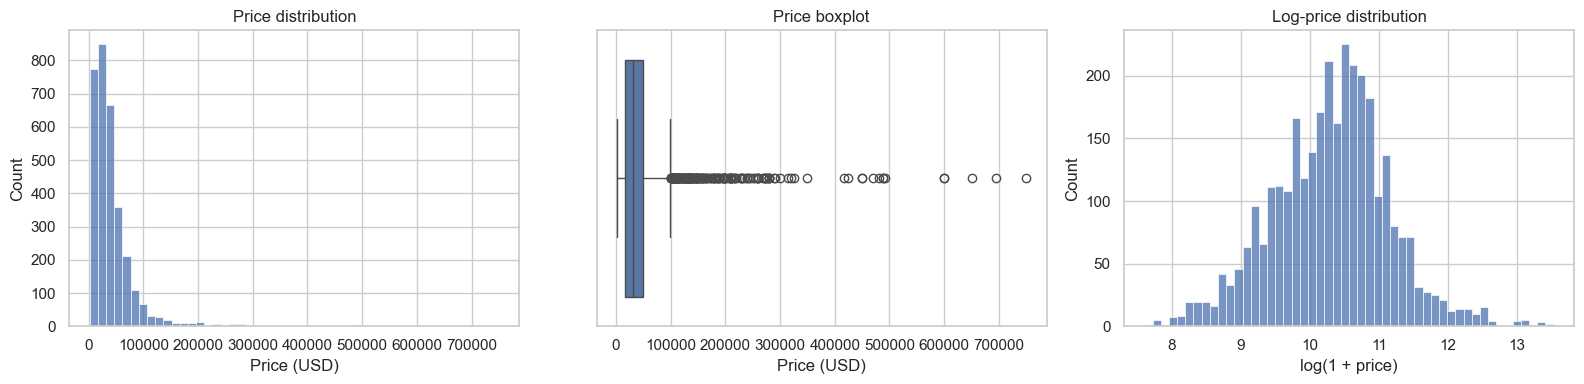

Price skewness: 5.66


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(
    data=eda, x="price", bins=50, ax=axes[0]
)
axes[0].set_title("Price distribution")
axes[0].set_xlabel("Price (USD)")

sns.boxplot(
    data=eda, x="price", ax=axes[1]
)
axes[1].set_title("Price boxplot")
axes[1].set_xlabel("Price (USD)")

sns.histplot(
    np.log1p(eda.loc[eda["price"] > 0, "price"]),
    bins=50,
    ax=axes[2]
)
axes[2].set_title("Log-price distribution")
axes[2].set_xlabel("log(1 + price)")

plt.tight_layout()
plt.show()

print("Price skewness:", round(eda["price"].skew(), 2))

Mileage and model year

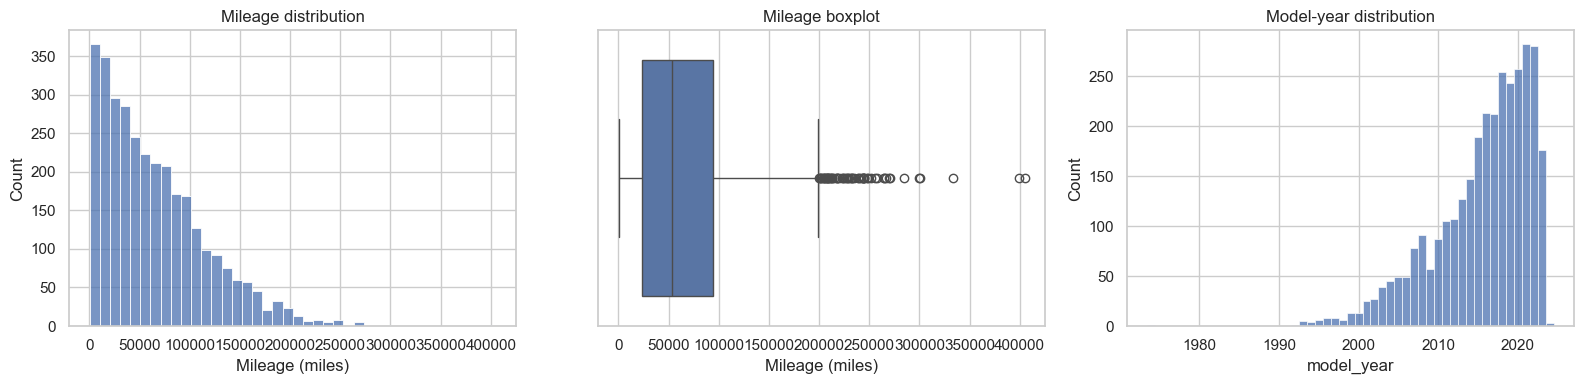

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(
    data=eda, x="milage", bins=40, ax=axes[0]
)
axes[0].set_title("Mileage distribution")
axes[0].set_xlabel("Mileage (miles)")

sns.boxplot(
    data=eda, x="milage", ax=axes[1]
)
axes[1].set_title("Mileage boxplot")
axes[1].set_xlabel("Mileage (miles)")

sns.histplot(
    data=eda, x="model_year", discrete=True, ax=axes[2]
)
axes[2].set_title("Model-year distribution")

plt.tight_layout()
plt.show()

Numerical relationships with price

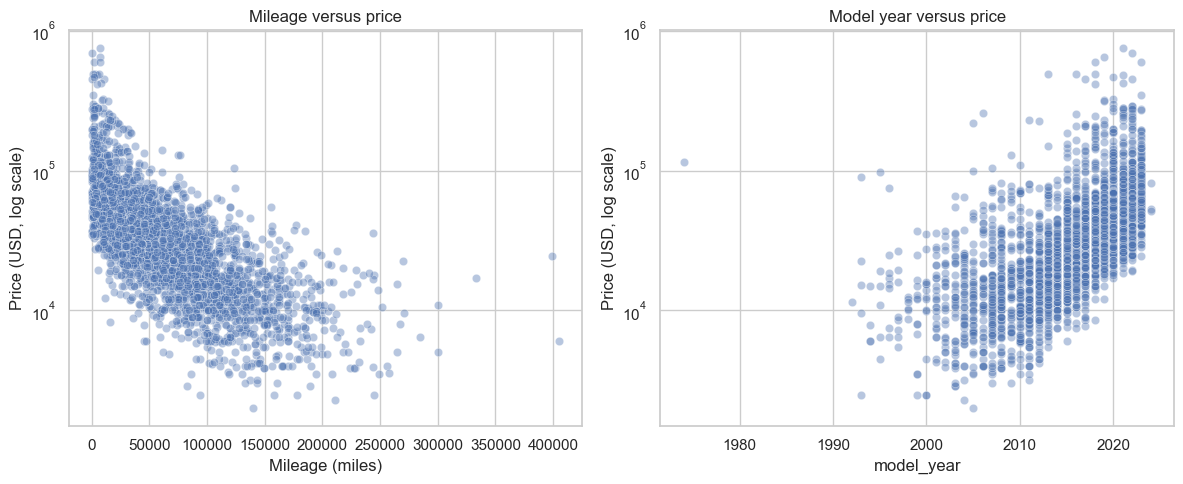

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(
    data=eda,
    x="milage",
    y="price",
    alpha=0.4,
    ax=axes[0]
)
axes[0].set_yscale("log")
axes[0].set_title("Mileage versus price")
axes[0].set_xlabel("Mileage (miles)")
axes[0].set_ylabel("Price (USD, log scale)")

sns.scatterplot(
    data=eda,
    x="model_year",
    y="price",
    alpha=0.4,
    ax=axes[1]
)
axes[1].set_yscale("log")
axes[1].set_title("Model year versus price")
axes[1].set_ylabel("Price (USD, log scale)")

plt.tight_layout()
plt.show()

categorical values

In [11]:
categorical_columns = [
    "brand",
    "model",
    "fuel_type",
    "engine",
    "transmission",
    "ext_col",
    "int_col",
    "accident",
    "clean_title"
]

for column in categorical_columns:
    print("\nCOLUMN:", column)
    print("Unique values:", eda[column].nunique())
    display(eda[column].value_counts(dropna=False).head(10))


COLUMN: brand
Unique values: 56


brand
Ford             310
BMW              310
Mercedes-Benz    263
Chevrolet        231
Porsche          157
Toyota           147
Audi             146
Lexus            136
Jeep             120
Land             102
Name: count, dtype: int64


COLUMN: model
Unique values: 1634


model
M3 Base               23
Corvette Base         18
F-150 XLT             17
Model Y Long Range    16
911 Carrera           16
Wrangler Sport        16
Camaro 2SS            15
Mustang GT Premium    14
1500 Laramie          13
F-150 Lariat          13
Name: count, dtype: int64


COLUMN: fuel_type
Unique values: 7


...

int_col
Black        1630
Beige         433
Gray          357
Brown         125
–             116
White         105
Red           103
Jet Black      42
Ebony          34
Blue           24
Name: count, dtype: int64


COLUMN: accident
Unique values: 2


accident
None reported                             2332
At least 1 accident or damage reported     784
NaN                                         91
Name: count, dtype: int64


COLUMN: clean_title
Unique values: 1


clean_title
Yes    2737
NaN     470
Name: count, dtype: int64

Visualize important category

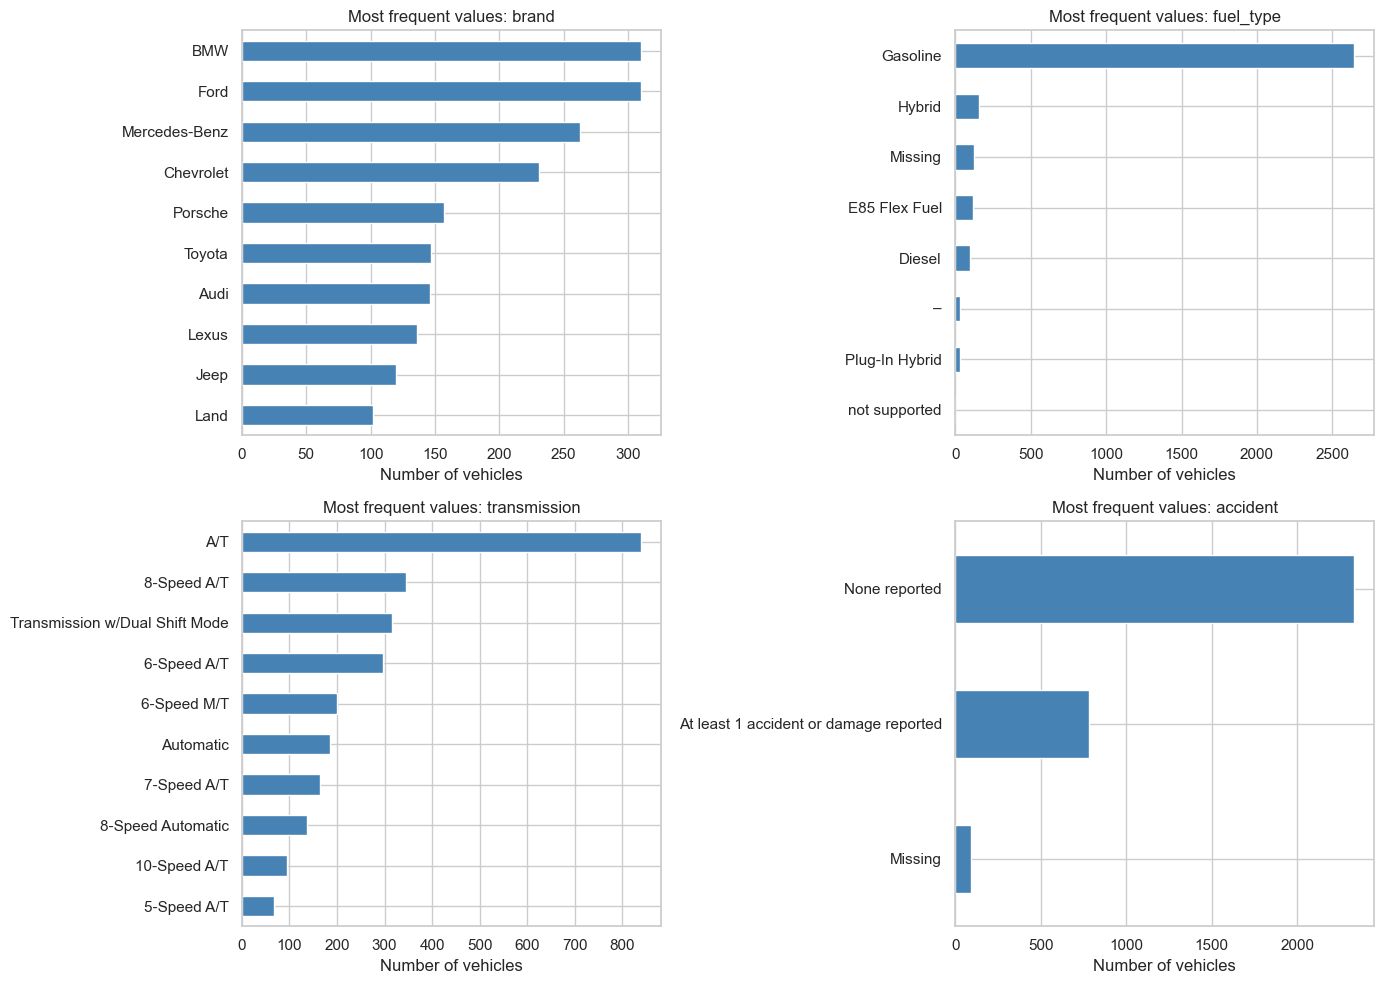

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for column, axis in zip(
    ["brand", "fuel_type", "transmission", "accident"],
    axes.flatten()
):
    counts = (
        eda[column]
        .fillna("Missing")
        .value_counts()
        .head(10)
    )

    counts.sort_values().plot(
        kind="barh",
        ax=axis,
        color="steelblue"
    )

    axis.set_title(f"Most frequent values: {column}")
    axis.set_xlabel("Number of vehicles")
    axis.set_ylabel("")

plt.tight_layout()
plt.show()

Compare price across categories

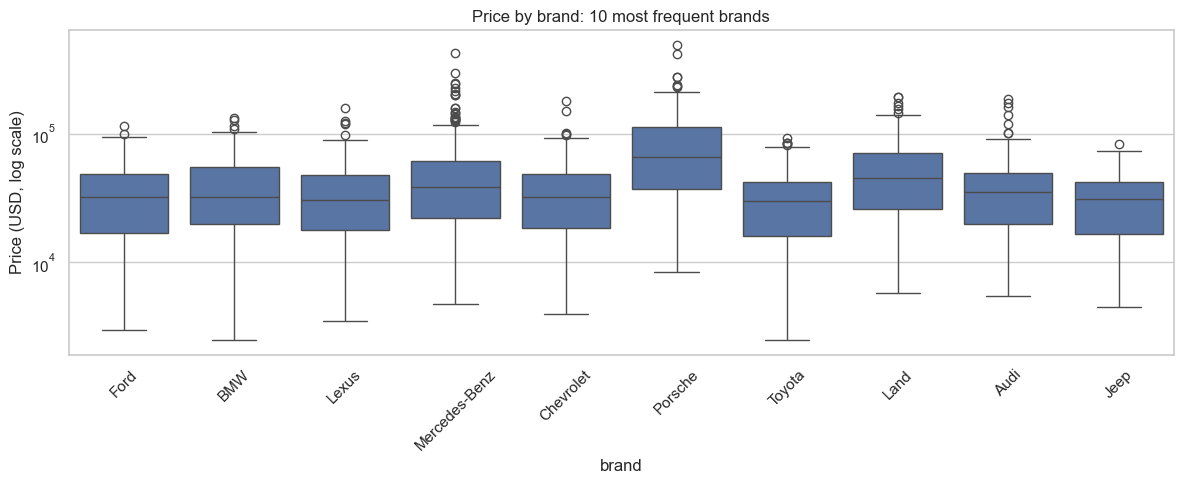

In [13]:
top_brands = eda["brand"].value_counts().head(10).index

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=eda[eda["brand"].isin(top_brands)],
    x="brand",
    y="price"
)

plt.yscale("log")
plt.title("Price by brand: 10 most frequent brands")
plt.ylabel("Price (USD, log scale)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

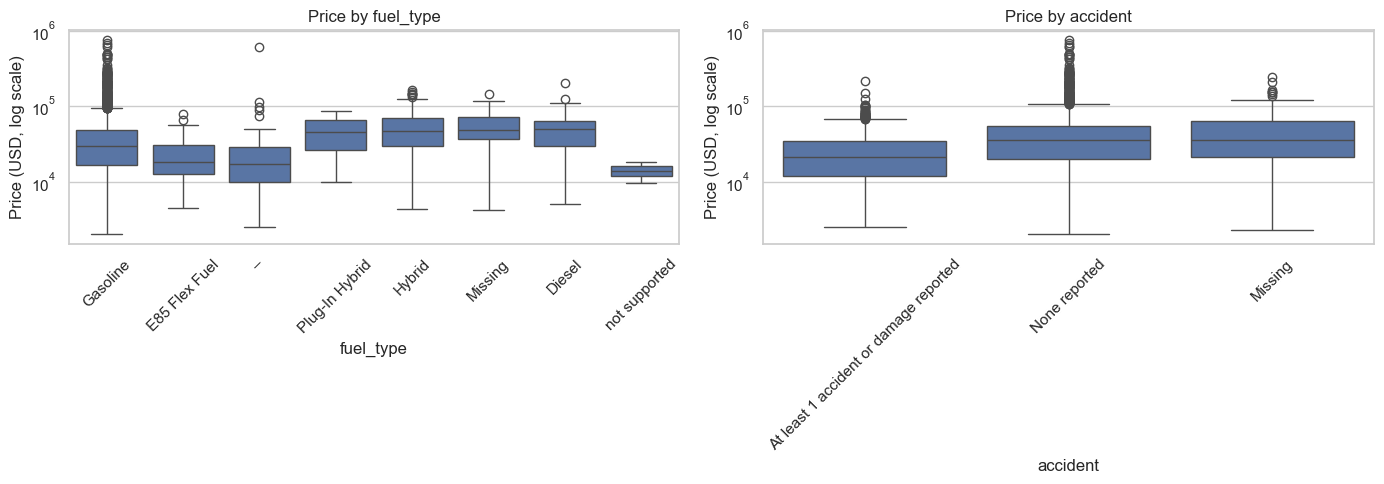


Price summary by: fuel_type


,count,median,mean
fuel_type,,,
Diesel,95,49883.0,50006.82
E85 Flex Fuel,117,18500.0,22329.23
Gasoline,2643,29950.0,42608.80
Hybrid,158,47299.0,52550.92
Plug-In Hybrid,30,44945.0,46955.70
not supported,2,14000.0,14000.00
–,35,17000.0,42185.03
NaN,127,48500.0,55983.43



Price summary by: accident


,count,median,mean
accident,,,
At least 1 accident or damage reported,784,20925.0,26054.60
None reported,2332,35750.0,48578.38
NaN,91,35645.0,50469.34



Price summary by: clean_title


,count,median,mean
clean_title,,,
Yes,2737,29000.0,40278.61
NaN,470,42900.0,59705.85


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for column, axis in zip(
    ["fuel_type", "accident"],
    axes
):
    plot_data = eda.copy()
    plot_data[column] = plot_data[column].fillna("Missing")

    sns.boxplot(
        data=plot_data,
        x=column,
        y="price",
        ax=axis
    )

    axis.set_yscale("log")
    axis.set_title(f"Price by {column}")
    axis.set_ylabel("Price (USD, log scale)")
    axis.tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

for column in ["fuel_type", "accident", "clean_title"]:
    print("\nPrice summary by:", column)

    display(
        eda.groupby(column, dropna=False)["price"]
        .agg(["count", "median", "mean"])
        .round(2)
    )

Numerical correlations

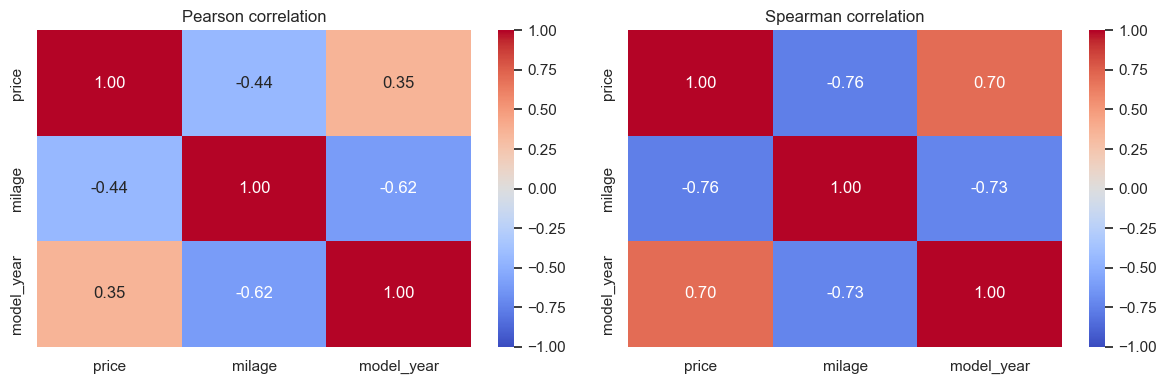

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(
    eda[numeric_columns].corr(method="pearson"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[0]
)
axes[0].set_title("Pearson correlation")

sns.heatmap(
    eda[numeric_columns].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1]
)
axes[1].set_title("Spearman correlation")

plt.tight_layout()
plt.show()

Extreme records and rare categories

In [16]:
print("10 highest-priced vehicles:")
display(
    eda.nlargest(10, "price")[
        ["brand", "model", "model_year", "milage", "engine", "price"]
    ]
)

print("10 highest-mileage vehicles:")
display(
    eda.nlargest(10, "milage")[
        ["brand", "model", "model_year", "milage", "price"]
    ]
)

print("10 oldest vehicles:")
display(
    eda.nsmallest(10, "model_year")[
        ["brand", "model", "model_year", "milage", "price"]
    ]
)

for column in ["model", "engine", "transmission", "ext_col", "int_col"]:
    counts = eda[column].value_counts()

    print(
        column,
        "| Unique categories:", len(counts),
        "| Categories appearing once:", (counts == 1).sum()
    )

10 highest-priced vehicles:


,brand,model,model_year,milage,engine,price
1356,Lamborghini,Aventador SVJ Base,2021,6987,6.5L V12 48V MPFI DOHC,749950
624,Rolls-Royce,Cullinan,2022,398,6.7L V12 48V GDI DOHC Twin Turbo,695000
979,Lamborghini,Aventador SVJ Base,2019,6929,759.0HP 6.5L 12 Cylinder Engine Gasoline Fuel,649999
1615,Rolls-Royce,Phantom,2023,1560,–,599995
1508,Rolls-Royce,Phantom,2018,7585,6.8L V12 48V GDI DOHC Twin Turbo,599000
3655,Lamborghini,Aventador S Base,2018,5858,729.0HP 6.5L 12 Cylinder Engine Gasoline Fuel,491836
1148,Porsche,911 R,2016,719,4.0L H6 24V GDI DOHC,489000
304,Rolls-Royce,Phantom Drophead Coupe Drophead,2013,2958,6.8L V12 48V GDI DOHC,488880
2133,Cadillac,Escalade ESV Sport,2021,4283,6.2L V8 16V GDI OHV,479995
1597,Ferrari,812 Superfast Base,2020,1575,788.0HP 6.5L 12 Cylinder Engine Gasoline Fuel,469900


10 highest-mileage vehicles:


,brand,model,model_year,milage,price
2764,Honda,Accord Sport,2013,405000,6000
3348,Mercedes-Benz,Sprinter 2500,2016,399000,24500
2175,Ford,Excursion Limited,2001,333361,17000
31,Dodge,Ram 1500 Laramie Mega Cab,2006,300183,10900
1145,GMC,Sierra 3500 SLE,2002,300000,5000
3118,Dodge,Dakota Sport,1997,285000,6399
3747,Ford,F-150 Lariat SuperCrew,2004,271000,9500
2558,Toyota,Land Cruiser Base,2010,269885,22500
3158,Toyota,4Runner 4WD,1999,267000,8000
3601,Toyota,Land Cruiser Base,2000,265000,15500


10 oldest vehicles:


,brand,model,model_year,milage,price
855,Ford,Bronco,1974,6217,115000
1088,Mazda,MX-5 Miata Base,1992,125800,11500
1134,Mercedes-Benz,E-Class 400E,1993,106983,15300
2303,Acura,NSX Base,1993,75980,90200
692,Honda,Civic EX,1993,58981,9599
2026,Mercedes-Benz,E-Class D 2.5 Turbo,1993,70015,22500
3922,Mazda,Protege DX,1993,94200,2500
2447,Chevrolet,1500 Cheyenne,1994,170443,6000
2608,Jeep,Wrangler S,1994,50750,15000
3039,Cadillac,DeVille Base,1994,85000,7900


model | Unique categories: 1634 | Categories appearing once: 968
engine | Unique categories: 1038 | Categories appearing once: 489
transmission | Unique categories: 60 | Categories appearing once: 21
ext_col | Unique categories: 271 | Categories appearing once: 186
int_col | Unique categories: 135 | Categories appearing once: 91


Preproceesing

Converting price to numbers

In [17]:
df["price"] = pd.to_numeric(
    df["price"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

In [18]:
df["milage"] = pd.to_numeric(
    df["milage"].astype(str)
    .str.replace("mi.", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

In [19]:
display(df[["price", "milage"]].head(10))

,price,milage
0,10300,51000
1,38005,34742
2,54598,22372
3,15500,88900
4,34999,9835
5,14798,136397
6,31000,84000
7,7300,242000
8,41927,23436
9,69950,34000


In [20]:
print(df[["price", "milage"]].dtypes)

price     int64
milage    int64
dtype: object


In [21]:
print("Missing price:", df["price"].isna().sum())
print("Non-positive price:", (df["price"] <= 0).sum())
print("Negative mileage:", (df["milage"] < 0).sum())

Missing price: 0
Non-positive price: 0
Negative mileage: 0


In [22]:
# Remove rows without a valid target price.
df = df.loc[df["price"].notna() & (df["price"] > 0)]

# Mark negative mileage as missing.
df.loc[df["milage"] < 0, "milage"] = np.nan

In [23]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


cleaned dataset

In [24]:
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000.0,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,2021,34742.0,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,2022,22372.0,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598
3,INFINITI,Q50 Hybrid Sport,2015,88900.0,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500
4,Audi,Q3 45 S line Premium Plus,2021,9835.0,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999



Data types:
brand            object
model            object
model_year        int64
milage          float64
fuel_type        object
engine           object
transmission     object
ext_col          object
int_col          object
accident         object
clean_title      object
price             int64
dtype: object

Missing values:
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64


In [25]:
columns = [
    "fuel_type", "engine", "transmission",
    "ext_col", "int_col", "accident", "clean_title"
]

df[columns] = df[columns].fillna("Unknown")

In [26]:
print(df.isna().sum())

brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64


Feature Engineering

In [27]:
display(df[["engine", "transmission"]].head(10))

,engine,transmission
0,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T
1,3.8L V6 24V GDI DOHC,8-Speed Automatic
2,3.5 Liter DOHC,Automatic
3,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T
4,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic
5,2.4 Liter,F
6,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T
7,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T
8,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T
9,534.0HP Electric Motor Electric Fuel System,A/T


Extract horsepower

In [28]:
df["horsepower"] = pd.to_numeric(
    df["engine"].str.extract(r"(?i)(\d+(?:\.\d+)?)\s*HP")[0],
    errors="coerce"
)

display(df[["engine", "horsepower"]].head())

,engine,horsepower
0,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,300.0
1,3.8L V6 24V GDI DOHC,NaN
2,3.5 Liter DOHC,NaN
3,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,354.0
4,2.0L I4 16V GDI DOHC Turbo,NaN


Extract engine size in litres

In [29]:
df["engine_litres"] = pd.to_numeric(
    df["engine"].str.extract(
        r"(?i)(\d+(?:\.\d+)?)\s*(?:L\b|Liter)"
    )[0],
    errors="coerce"
)

display(df[["engine", "engine_litres"]].head())

,engine,engine_litres
0,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,3.7
1,3.8L V6 24V GDI DOHC,3.8
2,3.5 Liter DOHC,3.5
3,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,3.5
4,2.0L I4 16V GDI DOHC Turbo,2.0


Extract cylinder count

In [30]:
# Match descriptions such as V6, I4, H4 or W12.
layout_count = df["engine"].str.extract(
    r"(?i)\b[VIHW]\s*(\d+)\b"
)[0]

# Match descriptions such as "6 Cylinder".
named_count = df["engine"].str.extract(
    r"(?i)(\d+)\s*Cylinder"
)[0]

df["cylinders"] = pd.to_numeric(
    layout_count.fillna(named_count),
    errors="coerce"
)

display(df[["engine", "cylinders"]].head())

,engine,cylinders
0,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6.0
1,3.8L V6 24V GDI DOHC,6.0
2,3.5 Liter DOHC,NaN
3,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,6.0
4,2.0L I4 16V GDI DOHC Turbo,4.0


Extract the number of gears

In [31]:
df["gears"] = pd.to_numeric(
    df["transmission"].str.extract(
        r"(?i)(\d+)\s*[- ]?\s*Speed"
    )[0],
    errors="coerce"
)

display(df[["transmission", "gears"]].head())

,transmission,gears
0,6-Speed A/T,6.0
1,8-Speed Automatic,8.0
2,Automatic,NaN
3,7-Speed A/T,7.0
4,8-Speed Automatic,8.0


Group transmission types

In [32]:
transmission_text = df["transmission"].str.lower()

df["transmission_type"] = np.select(
    [
        transmission_text.str.contains("dual|dct", na=False),
        transmission_text.str.contains("cvt|continuously", na=False),
        transmission_text.str.contains("automatic|a/t", na=False),
        transmission_text.str.contains("manual|m/t", na=False),
        transmission_text.eq("unknown")
    ],
    [
        "Dual clutch",
        "CVT",
        "Automatic",
        "Manual",
        "Unknown"
    ],
    default="Other"
)

display(df[["transmission", "transmission_type"]].head(10))

,transmission,transmission_type
0,6-Speed A/T,Automatic
1,8-Speed Automatic,Automatic
2,Automatic,Automatic
3,7-Speed A/T,Automatic
4,8-Speed Automatic,Automatic
5,F,Other
6,6-Speed A/T,Automatic
7,A/T,Automatic
8,6-Speed A/T,Automatic
9,A/T,Automatic


Checking all new features

In [34]:
new_features = [
    "horsepower",
    "engine_litres",
    "cylinders",
    "gears",
    "transmission_type"
]

display(df[new_features].head(10))

print("Missing values in extracted features:")
print(df[new_features].isna().sum())

print("\nTransmission categories:")
print(df["transmission_type"].value_counts())

,horsepower,engine_litres,cylinders,gears,transmission_type
0,300.0,3.7,6.0,6.0,Automatic
1,NaN,3.8,6.0,8.0,Automatic
2,NaN,3.5,NaN,NaN,Automatic
3,354.0,3.5,6.0,7.0,Automatic
4,NaN,2.0,4.0,8.0,Automatic
5,NaN,2.4,NaN,NaN,Other
6,292.0,2.0,4.0,6.0,Automatic
7,282.0,4.4,8.0,NaN,Automatic
8,311.0,3.5,6.0,6.0,Automatic
9,534.0,NaN,NaN,NaN,Automatic


Missing values in extracted features:
horsepower            808
engine_litres         217
cylinders             420
gears                1851
transmission_type       0
dtype: int64

Transmission categories:
transmission_type
Automatic      3107
Dual clutch     402
Manual          372
CVT             100
Other            28
Name: count, dtype: int64


In [35]:
numeric_columns = [
    "model_year", "milage", "horsepower",
    "engine_litres", "cylinders", "gears"
]

categorical_columns = [
    "brand", "model", "fuel_type",
    "accident", "clean_title", "transmission_type"
]

X = df[numeric_columns + categorical_columns]
y = df["price"]

# Reuse the split created during EDA.
train_ids = train_indices[train_indices.isin(df.index)]
test_ids = test_indices[test_indices.isin(df.index)]

X_train = X.loc[train_ids]
X_test = X.loc[test_ids]

y_train = y.loc[train_ids]
y_test = y.loc[test_ids]

In [36]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [37]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [38]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

In [39]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (3207, 89)
Processed test shape: (802, 89)


In [40]:
preview = X_train_processed[:5]

if hasattr(preview, "toarray"):
    preview = preview.toarray()

display(pd.DataFrame(
    preview,
    columns=preprocessor.get_feature_names_out()
))

,numeric__model_year,numeric__milage,numeric__horsepower,numeric__engine_litres,numeric__cylinders,numeric__gears,categorical__brand_Acura,categorical__brand_Alfa,categorical__brand_Audi,categorical__brand_BMW,categorical__brand_Bentley,categorical__brand_Buick,categorical__brand_Cadillac,categorical__brand_Chevrolet,categorical__brand_Chrysler,categorical__brand_Dodge,categorical__brand_Ferrari,categorical__brand_Ford,categorical__brand_GMC,categorical__brand_Genesis,categorical__brand_Honda,categorical__brand_Hummer,categorical__brand_Hyundai,categorical__brand_INFINITI,categorical__brand_Jaguar,categorical__brand_Jeep,categorical__brand_Kia,categorical__brand_Lamborghini,categorical__brand_Land,categorical__brand_Lexus,categorical__brand_Lincoln,categorical__brand_MINI,categorical__brand_Maserati,categorical__brand_Mazda,categorical__brand_Mercedes-Benz,categorical__brand_Mitsubishi,categorical__brand_Nissan,categorical__brand_Pontiac,categorical__brand_Porsche,categorical__brand_RAM,categorical__brand_Rivian,categorical__brand_Subaru,categorical__brand_Tesla,categorical__brand_Toyota,categorical__brand_Volkswagen,categorical__brand_Volvo,categorical__brand_infrequent_sklearn,categorical__model_1500 Big Horn,categorical__model_1500 Laramie,categorical__model_911 Carrera,categorical__model_911 Carrera S,categorical__model_Camaro 2SS,categorical__model_Corvette Base,categorical__model_Corvette Stingray w/2LT,categorical__model_E-Class E 350 4MATIC,categorical__model_ES 350 Base,categorical__model_Explorer XLT,categorical__model_F-150 Lariat,categorical__model_F-150 XLT,categorical__model_F-250 Lariat,categorical__model_GX 460 Base,categorical__model_Highlander XLE,categorical__model_M3 Base,categorical__model_M4 Base,categorical__model_M5 Base,categorical__model_Model Y Long Range,categorical__model_Mustang GT Premium,categorical__model_R1S Adventure Package,categorical__model_Wrangler Sport,categorical__model_Wrangler Unlimited Sport,categorical__model_infrequent_sklearn,categorical__fuel_type_Diesel,categorical__fuel_type_E85 Flex Fuel,categorical__fuel_type_Gasoline,categorical__fuel_type_Hybrid,categorical__fuel_type_Plug-In Hybrid,categorical__fuel_type_Unknown,categorical__fuel_type_–,categorical__fuel_type_infrequent_sklearn,categorical__accident_At least 1 accident or damage reported,categorical__accident_None reported,categorical__accident_Unknown,categorical__clean_title_Unknown,categorical__clean_title_Yes,categorical__transmission_type_Automatic,categorical__transmission_type_CVT,categorical__transmission_type_Dual clutch,categorical__transmission_type_Manual,categorical__transmission_type_Other
0,0.404894,0.154635,-0.166535,-0.127151,-0.124813,-0.706104,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,1.233863,-1.048390,0.231747,1.182258,1.116348,2.302168,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
2,0.073307,-0.184876,0.865378,-0.490875,-0.124813,-0.706104,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,0.239101,0.235722,-0.211795,-0.127151,-0.124813,-0.706104,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0

Importing the modelling tools

In [41]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.model_selection import KFold, cross_validate

Defining the models

In [42]:
models = {
    "Median baseline": DummyRegressor(strategy="median"),

    "Ridge": Ridge(alpha=10, solver="lsqr"),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

Comparing using five-fold cross-validation

In [43]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        return_train_score=True,
        error_score="raise"
    )

    results.append({
        "Model": name,
        "Training MAE": -scores["train_MAE"].mean(),
        "CV MAE": -scores["test_MAE"].mean(),
        "CV MAE variation": scores["test_MAE"].std(),
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV R2": scores["test_R2"].mean()
    })

    print(name, "completed")

comparison = pd.DataFrame(results).sort_values("CV MAE")
display(comparison.round(2))

Median baseline completed
Ridge completed
Random Forest completed
Gradient Boosting completed


,Model,Training MAE,CV MAE,CV MAE variation,CV RMSE,CV R2
2,Random Forest,6512.70,10753.62,1434.50,25863.63,0.74
3,Gradient Boosting,12586.18,13544.02,1517.15,28441.48,0.68
1,Ridge,17299.33,17657.70,1223.35,35504.88,0.50
0,Median baseline,25577.56,25641.25,2553.01,51620.50,-0.05


Importing the tuning tool

In [44]:
from sklearn.model_selection import GridSearchCV

settings to compare

In [45]:
parameter_grids = {
    "Ridge": {
        "model__alpha": [1, 10, 100]
    },

    "Random Forest": {
        "model__max_depth": [None, 15],
        "model__min_samples_leaf": [2, 3, 5]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.05, 0.1]
    }
}

alpha: controls Ridge regularization.
max_depth: limits tree complexity.
min_samples_leaf: helps prevent trees from memorizing small groups.
n_estimators: number of boosting trees.
learning_rate: contribution of each boosting tree.

Running tuning and display results

In [47]:
tuned_models = {}
tuning_results = []

for name, parameters in parameter_grids.items():
    print("Tuning:", name, flush=True)

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clone(models[name]))
    ])

    search = GridSearchCV(
        pipeline,
        param_grid=parameters,
        scoring="neg_mean_absolute_error",
        cv=cv,
        n_jobs=1,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Tuned CV MAE": -search.best_score_,
        "Best parameters": search.best_params_
    })

    display(pd.DataFrame(tuning_results))

tuning_comparison = pd.DataFrame(
    tuning_results
).sort_values("Tuned CV MAE")

display(tuning_comparison)

Tuning: Ridge


,Model,Tuned CV MAE,Best parameters
0,Ridge,17373.058994,{'model__alpha': 1}


Tuning: Random Forest


,Model,Tuned CV MAE,Best parameters
0,Ridge,17373.058994,{'model__alpha': 1}
1,Random Forest,10443.199154,"{'model__max_depth': None, 'model__min_samples..."


Tuning: Gradient Boosting


,Model,Tuned CV MAE,Best parameters
0,Ridge,17373.058994,{'model__alpha': 1}
1,Random Forest,10443.199154,"{'model__max_depth': None, 'model__min_samples..."
2,Gradient Boosting,11994.716080,"{'model__learning_rate': 0.1, 'model__n_estima..."


,Model,Tuned CV MAE,Best parameters
1,Random Forest,10443.199154,"{'model__max_depth': None, 'model__min_samples..."
2,Gradient Boosting,11994.716080,"{'model__learning_rate': 0.1, 'model__n_estima..."
0,Ridge,17373.058994,{'model__alpha': 1}


Comparing original and tuned candidates

In [48]:
original_results = comparison[["Model", "CV MAE"]].copy()
original_results["Version"] = "Original"

tuned_results = tuning_comparison[
    ["Model", "Tuned CV MAE"]
].rename(columns={"Tuned CV MAE": "CV MAE"})

tuned_results["Version"] = "Tuned"

all_results = pd.concat(
    [original_results, tuned_results],
    ignore_index=True
).sort_values("CV MAE")

display(all_results.round(2))

,Model,CV MAE,Version
4,Random Forest,10443.20,Tuned
0,Random Forest,10753.62,Original
5,Gradient Boosting,11994.72,Tuned
1,Gradient Boosting,13544.02,Original
6,Ridge,17373.06,Tuned
2,Ridge,17657.70,Original
3,Median baseline,25641.25,Original


Selecting the candidate with the lowest CV MAE

In [49]:
winner = all_results.iloc[0]

best_name = winner["Model"]

if winner["Version"] == "Tuned":
    best_model = tuned_models[best_name]
else:
    best_model = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clone(models[best_name]))
    ])

best_model.fit(X_train, y_train)

print("Selected model:", best_name)
print("Version:", winner["Version"])

Selected model: Random Forest
Version: Tuned


Evaluating it on the untouched test set

In [50]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y_pred = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)

print(f"Test MAE: ${test_mae:,.2f}")
print(f"Test RMSE: ${test_rmse:,.2f}")
print(f"Test R²: {test_r2:.3f}")

Test MAE: $17,082.90
Test RMSE: $128,888.64
Test R²: 0.187


Comparing actual and predicted prices

In [51]:
prediction_results = pd.DataFrame({
    "Actual price": y_test,
    "Predicted price": y_pred
})

prediction_results["Absolute error"] = abs(
    prediction_results["Actual price"]
    - prediction_results["Predicted price"]
)

display(prediction_results.head(10).round(2))

,Actual price,Predicted price,Absolute error
2580,28000,28915.76,915.76
3660,5900,11126.78,5226.78
897,41000,47200.91,6200.91
2091,40250,46415.13,6165.13
1044,77999,63704.46,14294.54
2320,35899,33983.36,1915.64
465,36000,35577.49,422.51
196,47214,63108.54,15894.54
3113,30900,12668.80,18231.20
3553,11000,7677.22,3322.78


Visualize prediction errors

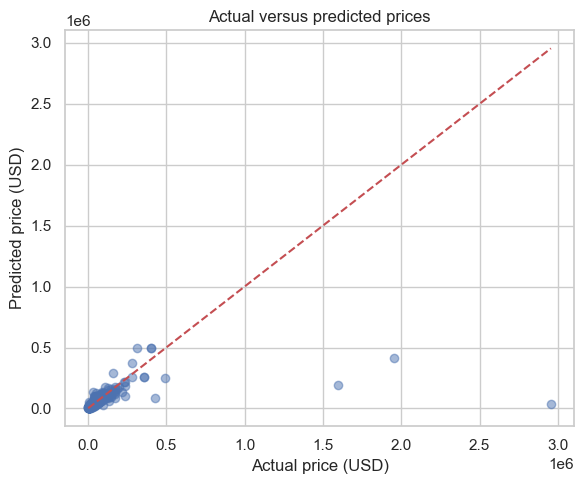

In [52]:
plt.figure(figsize=(6, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot([minimum, maximum], [minimum, maximum], "r--")

plt.xlabel("Actual price (USD)")
plt.ylabel("Predicted price (USD)")
plt.title("Actual versus predicted prices")
plt.tight_layout()
plt.show()

Saving the complete pipeline

In [53]:
import joblib

joblib.dump(best_model, "used_car_pipeline.joblib", compress=3)

print("Model and preprocessing pipeline saved.")

Model and preprocessing pipeline saved.


Verifing the saved model

In [54]:
loaded_model = joblib.load("used_car_pipeline.joblib")

sample = X_test.head(5)

np.testing.assert_allclose(
    best_model.predict(sample),
    loaded_model.predict(sample)
)

print("Saved-model predictions match.")

Saved-model predictions match.


In [55]:
import json

app_details = {
    "categories": {
        column: sorted(X_train[column].dropna().unique().tolist())
        for column in categorical_columns
    },
    "metrics": {
        "MAE": float(test_mae),
        "RMSE": float(test_rmse),
        "R2": float(test_r2)
    }
}

with open("app_details.json", "w") as file:
    json.dump(app_details, file, indent=2)

print("Application details saved.")

Application details saved.


In [56]:
%%writefile app.py
from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd
import streamlit as st

ROOT = Path(__file__).resolve().parent

st.set_page_config(page_title="Used Car Price Prediction")
st.title("Used Car Price Prediction")
st.write("Estimate a vehicle's listing price in US dollars.")


@st.cache_resource
def load_pipeline():
    return joblib.load(ROOT / "used_car_pipeline.joblib")


pipeline = load_pipeline()

with open(ROOT / "app_details.json") as file:
    details = json.load(file)

categories = details["categories"]

with st.form("vehicle_form"):

    brand = st.selectbox("Brand", categories["brand"])
    model = st.selectbox("Model", categories["model"])

    model_year = st.number_input(
        "Model year",
        min_value=1974,
        max_value=2024,
        value=2020
    )

    mileage = st.number_input(
        "Mileage in miles",
        min_value=0,
        value=50000,
        step=1000
    )

    fuel_type = st.selectbox(
        "Fuel type", categories["fuel_type"]
    )

    accident = st.selectbox(
        "Accident history", categories["accident"]
    )

    clean_title = st.selectbox(
        "Clean title", categories["clean_title"]
    )

    transmission_type = st.selectbox(
        "Transmission type",
        categories["transmission_type"]
    )

    st.write("Leave unavailable engine or gear details as unknown.")

    horsepower_known = st.checkbox("Horsepower is known")
    horsepower = st.number_input(
        "Horsepower", min_value=1.0, value=200.0
    )

    litres_known = st.checkbox("Engine size is known")
    engine_litres = st.number_input(
        "Engine size in litres", min_value=0.1, value=2.0
    )

    cylinders_known = st.checkbox("Cylinder count is known")
    cylinders = st.number_input(
        "Cylinders", min_value=1, value=4
    )

    gears_known = st.checkbox("Gear count is known")
    gears = st.number_input(
        "Gears", min_value=1, value=6
    )

    submitted = st.form_submit_button("Predict price")

if submitted:

    vehicle = pd.DataFrame([{
        "model_year": model_year,
        "milage": mileage,
        "horsepower": horsepower if horsepower_known else np.nan,
        "engine_litres": engine_litres if litres_known else np.nan,
        "cylinders": cylinders if cylinders_known else np.nan,
        "gears": gears if gears_known else np.nan,
        "brand": brand,
        "model": model,
        "fuel_type": fuel_type,
        "accident": accident,
        "clean_title": clean_title,
        "transmission_type": transmission_type
    }])

    prediction = float(pipeline.predict(vehicle)[0])

    if np.isfinite(prediction) and prediction > 0:
        st.metric("Estimated listing price", f"${prediction:,.2f}")
    else:
        st.warning("Invalid prediction. Check the vehicle details.")

st.subheader("Held-out test performance")

metrics = details["metrics"]

st.write(f"MAE: ${metrics['MAE']:,.2f}")
st.write(f"RMSE: ${metrics['RMSE']:,.2f}")
st.write(f"R²: {metrics['R2']:.3f}")

st.caption(
    "This estimates historical listing prices, not guaranteed selling "
    "prices. Rare vehicles and extreme prices may have larger errors. "
    "MAE is an average error, not a prediction interval."
)

Writing app.py


In [59]:
import os
print(os.getcwd())


C:\Users\R Prithesa\Documents\used car price prediction


In [61]:
from importlib.metadata import version

packages = [
    "pandas", "numpy", "scipy",
    "scikit-learn", "joblib", "streamlit"
]

with open("requirements.txt", "w") as file:
    for package in packages:
        file.write(f"{package}=={version(package)}\n")

print("requirements.txt created successfully.")

requirements.txt created successfully.


In [62]:
with open("requirements.txt") as file:
    print(file.read())

pandas==2.3.3
numpy==2.3.5
scipy==1.16.3
scikit-learn==1.7.2
joblib==1.5.2
streamlit==1.51.0



In [64]:
%%writefile README.md
# Used Car Price Prediction

## Objective
Estimate used-car listing prices in US dollars.

## Workflow
EDA, data cleaning, feature engineering, encoding and scaling.
Compare Ridge, Random Forest and Gradient Boosting with a median baseline.
Apply five-fold cross-validation and hyperparameter tuning.
Evaluate the selected model using test MAE, RMSE and R².

## Leakage Prevention
Fit preprocessing inside model pipelines.
Keep test data separate from model selection.

## Run the Application
python -m pip install -r requirements.txt
python -m streamlit run app.py

## Limitations
Predictions estimate historical listing prices.
Rare vehicles and extreme prices may have larger errors.

Writing README.md
